# 01 | NUTS levels (PT + ES)

Builds the four NUTS levels (0 to 3) for Portugal and Spain from the Eurostat/GISCO dataset.

**Source:** [Eurostat GISCO – Territorial units for statistics (NUTS)](https://ec.europa.eu/eurostat/web/gisco/geodata/statistical-units/territorial-units-statistics)
* **NUTS year:** 2024
* **File format:** GeoPackage
* **Geometry type:** Polygons (RG)
* **Scale:** 01M
* **CRS:** EPSG:4326

**Input:** `data/raw/NUTS_RG_01M_2024_4326.gpkg`
**Output (layers in `data/processed/layers.gpkg`):** `NUTS0_2024_PT_ES`, `NUTS1_2024_PT_ES`, `NUTS2_2024_PT_ES`, `NUTS3_2024_PT_ES`

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *

## Load and explore

In [2]:
gdf_nuts = gpd.read_file(RAW_DIR / "NUTS_RG_01M_2024_4326.gpkg")
gdf_nuts.head()

,NUTS_ID,LEVL_CODE,CNTR_CODE,NAME_LATN,NUTS_NAME,MOUNT_TYPE,URBN_TYPE,COAST_TYPE,geometry
0,AL011,3,AL,Dibër,Dibër,NaN,NaN,NaN,"POLYGON ((20.3461 41.8761, 20.34106 41.85659, ..."
1,AL012,3,AL,Durrës,Durrës,NaN,NaN,NaN,"POLYGON ((19.8072 41.5662, 19.81828 41.56444, ..."
2,AL013,3,AL,Kukës,Kukës,NaN,NaN,NaN,"POLYGON ((20.11943 42.52485, 20.16464 42.50607..."
3,AL031,3,AL,Berat,Berat,NaN,NaN,NaN,"POLYGON ((19.96849 40.86741, 19.96939 40.86439..."
4,AL032,3,AL,Fier,Fier,NaN,NaN,NaN,"POLYGON ((19.62572 41.06464, 19.62615 41.06414..."


In [3]:
gdf_nuts.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
print(gdf_nuts["MOUNT_TYPE"].unique())
print(gdf_nuts["URBN_TYPE"].unique())
print(gdf_nuts["COAST_TYPE"].unique())

[nan  1.  0.]
[nan  1.  3.  2.]
[nan  1.]


## Filter Portugal and Spain

In [5]:
gdf_nuts_PT_ES = gdf_nuts[gdf_nuts["CNTR_CODE"].isin(["PT", "ES"])].copy()

columns_to_drop = ["CNTR_CODE", "NAME_LATN"]
gdf_nuts_PT_ES = gdf_nuts_PT_ES.drop(columns=columns_to_drop)

new_column_names = {
    "LEVL_CODE": "Level",
    "NUTS_NAME": "NUTS_Name",
    "MOUNT_TYPE": "MountainType",
    "URBN_TYPE": "UrbanType",
    "COAST_TYPE": "CoastalType",
}
gdf_nuts_PT_ES = gdf_nuts_PT_ES.rename(columns=new_column_names)
gdf_nuts_PT_ES.head()

,NUTS_ID,Level,NUTS_Name,MountainType,UrbanType,CoastalType,geometry
524,ES120,3,Asturias,1.0,2.0,1.0,"MULTIPOLYGON (((-5.83099 43.64236, -5.82892 43..."
525,ES423,3,Cuenca,NaN,2.0,NaN,"POLYGON ((-2.15693 40.65871, -2.1521 40.65771,..."
526,ES243,3,Zaragoza,1.0,1.0,NaN,"POLYGON ((-0.90304 42.70149, -0.88012 42.69393..."
529,ES413,3,León,1.0,2.0,NaN,"POLYGON ((-4.85075 43.17325, -4.84444 43.16952..."
531,ES424,3,Guadalajara,1.0,2.0,NaN,"MULTIPOLYGON (((-2.90285 41.32594, -2.89795 41..."


Quick look at the mountain and coastal regions (these typology fields are only filled at NUTS 3 level):

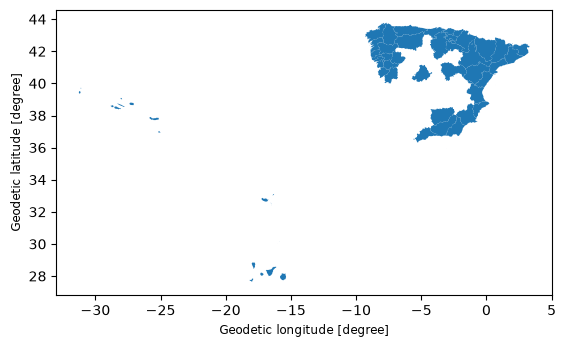

In [6]:
gdf_nuts_PT_ES[gdf_nuts_PT_ES["MountainType"] == 1.0].plot();

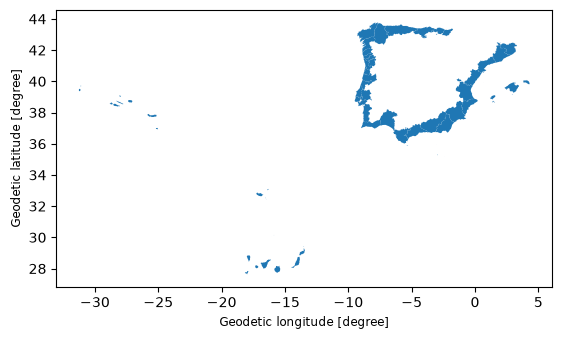

In [7]:
gdf_nuts_PT_ES[gdf_nuts_PT_ES["CoastalType"] == 1.0].plot();

## Split by level

For NUTS 0, 1 and 2 the typology fields (`MountainType`, `UrbanType`, `CoastalType`) are empty, so they are removed. For NUTS 3 they are kept.

### NUTS 0

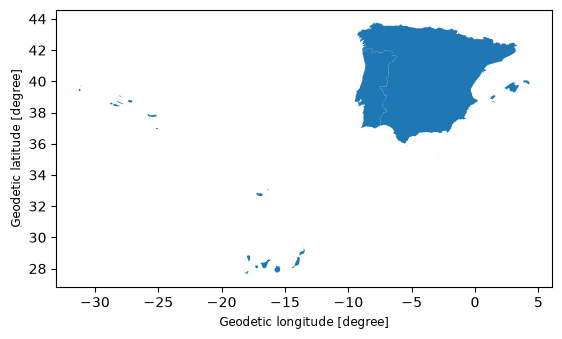

In [8]:
gdf_nuts0_PT_ES = gdf_nuts_PT_ES[gdf_nuts_PT_ES["Level"] == 0].copy()
gdf_nuts0_PT_ES = gdf_nuts0_PT_ES.drop(columns=["Level", "MountainType", "UrbanType", "CoastalType"])
gdf_nuts0_PT_ES = gdf_nuts0_PT_ES.rename(columns={"NUTS_ID": "NUTS0_ID", "NUTS_Name": "NUTS0_Name"})
gdf_nuts0_PT_ES.plot();

### NUTS 1

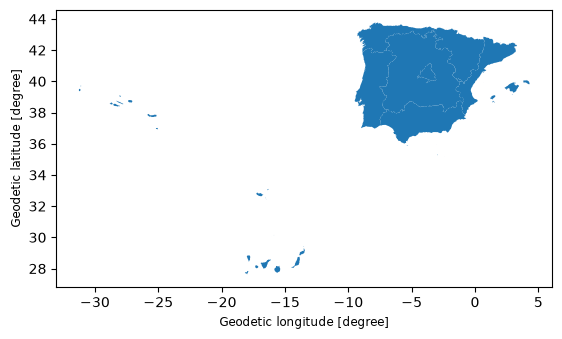

In [9]:
gdf_nuts1_PT_ES = gdf_nuts_PT_ES[gdf_nuts_PT_ES["Level"] == 1].copy()
gdf_nuts1_PT_ES = gdf_nuts1_PT_ES.drop(columns=["Level", "MountainType", "UrbanType", "CoastalType"])
gdf_nuts1_PT_ES = gdf_nuts1_PT_ES.rename(columns={"NUTS_ID": "NUTS1_ID", "NUTS_Name": "NUTS1_Name"})
gdf_nuts1_PT_ES.plot();

### NUTS 2

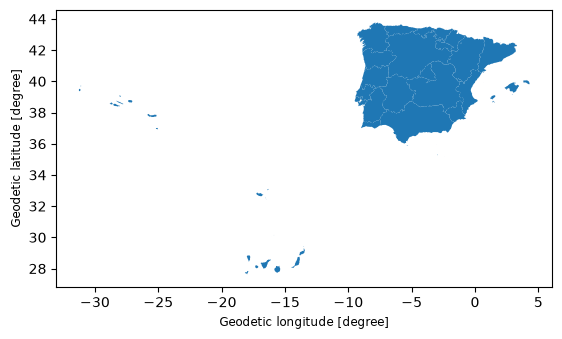

In [10]:
gdf_nuts2_PT_ES = gdf_nuts_PT_ES[gdf_nuts_PT_ES["Level"] == 2].copy()
gdf_nuts2_PT_ES = gdf_nuts2_PT_ES.drop(columns=["Level", "MountainType", "UrbanType", "CoastalType"])
gdf_nuts2_PT_ES = gdf_nuts2_PT_ES.rename(columns={"NUTS_ID": "NUTS2_ID", "NUTS_Name": "NUTS2_Name"})
gdf_nuts2_PT_ES.plot();

### NUTS 3

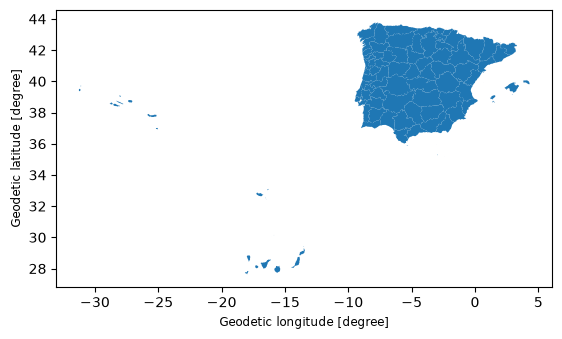

In [11]:
gdf_nuts3_PT_ES = gdf_nuts_PT_ES[gdf_nuts_PT_ES["Level"] == 3].copy()
gdf_nuts3_PT_ES = gdf_nuts3_PT_ES.drop(columns=["Level"])
gdf_nuts3_PT_ES = gdf_nuts3_PT_ES.rename(columns={"NUTS_ID": "NUTS3_ID", "NUTS_Name": "NUTS3_Name"})
gdf_nuts3_PT_ES.plot();

## Centroids and column order

In [12]:
gdf_nuts0_PT_ES = add_centroids(gdf_nuts0_PT_ES)[["NUTS0_ID", "NUTS0_Name", "LonCent", "LatCent", "geometry"]]
gdf_nuts1_PT_ES = add_centroids(gdf_nuts1_PT_ES)[["NUTS1_ID", "NUTS1_Name", "LonCent", "LatCent", "geometry"]]
gdf_nuts2_PT_ES = add_centroids(gdf_nuts2_PT_ES)[["NUTS2_ID", "NUTS2_Name", "LonCent", "LatCent", "geometry"]]
gdf_nuts3_PT_ES = add_centroids(gdf_nuts3_PT_ES)[
    ["NUTS3_ID", "NUTS3_Name", "MountainType", "UrbanType", "CoastalType", "LonCent", "LatCent", "geometry"]
]
gdf_nuts3_PT_ES.head()

,NUTS3_ID,NUTS3_Name,MountainType,UrbanType,CoastalType,LonCent,LatCent,geometry
524,ES120,Asturias,1.0,2.0,1.0,-5.993329,43.294005,"MULTIPOLYGON (((-5.83099 43.64236, -5.82892 43..."
525,ES423,Cuenca,NaN,2.0,NaN,-2.195305,39.895538,"POLYGON ((-2.15693 40.65871, -2.1521 40.65771,..."
526,ES243,Zaragoza,1.0,1.0,NaN,-1.063789,41.619723,"POLYGON ((-0.90304 42.70149, -0.88012 42.69393..."
529,ES413,León,1.0,2.0,NaN,-5.840476,42.620488,"POLYGON ((-4.85075 43.17325, -4.84444 43.16952..."
531,ES424,Guadalajara,1.0,2.0,NaN,-2.623185,40.814005,"MULTIPOLYGON (((-2.90285 41.32594, -2.89795 41..."


## Save

In [13]:
save_layer(gdf_nuts0_PT_ES, "NUTS0_2024_PT_ES")
save_layer(gdf_nuts1_PT_ES, "NUTS1_2024_PT_ES")
save_layer(gdf_nuts2_PT_ES, "NUTS2_2024_PT_ES")
save_layer(gdf_nuts3_PT_ES, "NUTS3_2024_PT_ES")

Saved layer 'NUTS0_2024_PT_ES' (2 rows)
Saved layer 'NUTS1_2024_PT_ES' (10 rows)
Saved layer 'NUTS2_2024_PT_ES' (28 rows)
Saved layer 'NUTS3_2024_PT_ES' (85 rows)


## Summary
* Loaded the NUTS 2024 file and kept only Portugal and Spain.
* Removed `CNTR_CODE` and `NAME_LATN` and renamed the remaining fields.
* Split the data into NUTS 0, 1, 2 and 3. The typology fields were removed from levels 0 to 2 because they are empty there.
* Added centroids (`LonCent`, `LatCent`), calculated in a projected CRS (EPSG:3035) and converted back to EPSG:4326.
* Saved the four layers for the next notebooks.